In [8]:
# Step 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Read the Cleaned Dataset

file_path = r"Output\Mobile_Reviews_Cleaned.csv"

df = pd.read_csv(file_path)

print("Cleaned dataset loaded successfully!")
print(f"Dataset Shape: {df.shape}")

Cleaned dataset loaded successfully!
Dataset Shape: (50000, 22)


In [3]:
# Step 3: Understand Dataset Structure

print("Dataset Shape:")
print(df.shape)

print("\n" + "=" * 60)

print("Column Names:")
print(df.columns.tolist())

print("\n" + "=" * 60)

print("Data Types:")
print(df.dtypes)

print("\n" + "=" * 60)

print("Dataset Information:")
df.info()

Dataset Shape:
(50000, 22)

Column Names:
['review_id', 'customer_name', 'age', 'brand', 'model', 'price_usd', 'price_local', 'currency', 'exchange_rate_to_usd', 'rating', 'sentiment', 'country', 'language', 'review_date', 'verified_purchase', 'battery_life_rating', 'camera_rating', 'performance_rating', 'design_rating', 'display_rating', 'helpful_votes', 'source']

Data Types:
review_id                 int64
customer_name               str
age                       int64
brand                       str
model                       str
price_usd               float64
price_local                 str
currency                    str
exchange_rate_to_usd    float64
rating                  float64
sentiment                   str
country                     str
language                    str
review_date                 str
verified_purchase          bool
battery_life_rating       int64
camera_rating             int64
performance_rating        int64
design_rating             int64
display_rat

In [5]:
# Step 4: Statistical Summary of Numerical Features

df.describe().round(2)

,review_id,age,price_usd,exchange_rate_to_usd,rating,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,25000.50,30.08,689.69,12.06,3.11,2.72,2.72,2.72,2.71,2.72,3.64
std,14433.90,8.93,310.10,26.55,1.25,1.35,1.35,1.35,1.34,1.35,2.43
min,1.00,18.00,180.02,0.78,1.00,1.00,1.00,1.00,1.00,1.00,0.00
25%,12500.75,23.00,451.04,1.00,2.00,1.00,1.00,1.00,1.00,1.00,2.00
50%,25000.50,29.00,637.12,1.53,3.00,3.00,3.00,3.00,3.00,3.00,3.00
75%,37500.25,36.00,900.92,5.70,4.00,4.00,4.00,4.00,4.00,4.00,5.00
max,50000.00,65.00,1499.89,83.00,5.00,5.00,5.00,5.00,5.00,5.00,17.00


In [6]:
# Step 5: Product Distribution by Brand

brand_counts = df['brand'].value_counts()

print("Number of Reviews by Brand:")
print(brand_counts)

Number of Reviews by Brand:
brand
Xiaomi      7241
Google      7234
Apple       7144
OnePlus     7136
Realme      7132
Motorola    7061
Samsung     7052
Name: count, dtype: int64


In [9]:
# Interactive Brand Distribution Chart with Data Labels

fig = px.bar(
    x=brand_counts.index,
    y=brand_counts.values,
    labels={
        'x': 'Brand',
        'y': 'Number of Reviews'
    },
    title='Distribution of Reviews by Brand',
    text=brand_counts.values
)

fig.update_traces(
    textposition='outside'
)

fig.update_layout(
    xaxis_title='Brand',
    yaxis_title='Number of Reviews'
)

fig.show()

In [10]:
# Step 6: Rating Distribution

rating_counts = df['rating'].value_counts().sort_index()

print("Rating Distribution:")
print(rating_counts)

Rating Distribution:
rating
1.0     6578
2.0     9921
3.0    11889
4.0    14608
5.0     7004
Name: count, dtype: int64


In [11]:
# Step 7: Price Analysis

print("Price Statistics (USD):")
print(df['price_usd'].describe().round(2))

Price Statistics (USD):
count    50000.00
mean       689.69
std        310.10
min        180.02
25%        451.04
50%        637.12
75%        900.92
max       1499.89
Name: price_usd, dtype: float64


In [12]:
# Step 8: Correlation Analysis

correlation_features = [
    'price_usd',
    'rating',
    'battery_life_rating',
    'camera_rating',
    'performance_rating',
    'design_rating',
    'display_rating',
    'helpful_votes'
]

correlation_matrix = df[correlation_features].corr().round(2)

correlation_matrix

,price_usd,rating,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,helpful_votes
price_usd,1.0,0.00,0.00,0.00,-0.00,0.00,-0.00,0.00
rating,0.0,1.00,0.75,0.75,0.75,0.75,0.75,0.47
battery_life_rating,0.0,0.75,1.00,0.59,0.58,0.59,0.58,0.36
camera_rating,0.0,0.75,0.59,1.00,0.58,0.58,0.58,0.36
performance_rating,-0.0,0.75,0.58,0.58,1.00,0.58,0.58,0.35
design_rating,0.0,0.75,0.59,0.58,0.58,1.00,0.58,0.35
display_rating,-0.0,0.75,0.58,0.58,0.58,0.58,1.00,0.35
helpful_votes,0.0,0.47,0.36,0.36,0.35,0.35,0.35,1.00


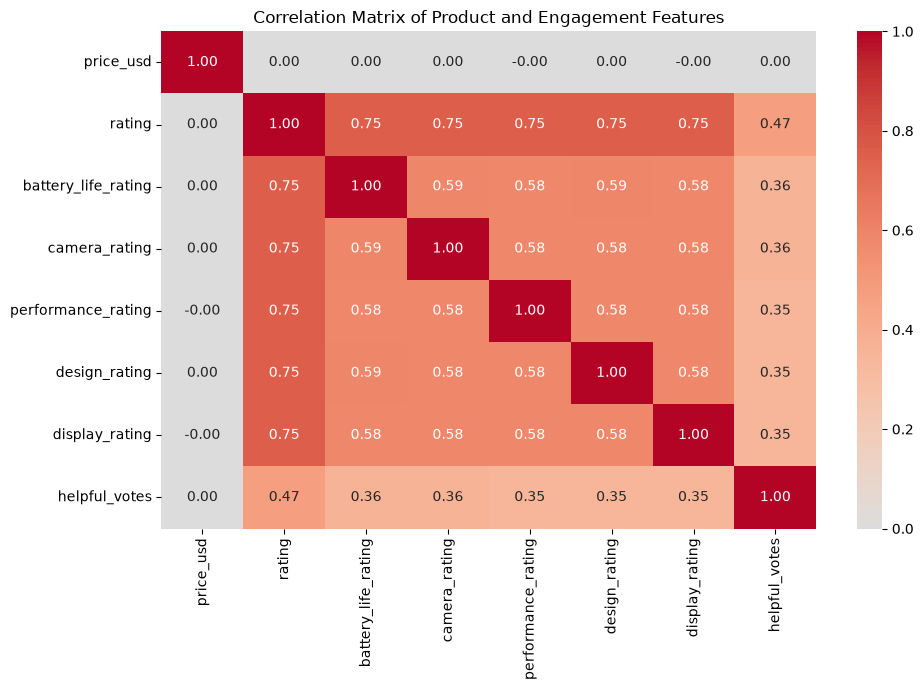

In [13]:
# Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix of Product and Engagement Features')
plt.tight_layout()
plt.show()

In [14]:
# Step 9: Average Product Specification Ratings

specification_features = [
    'battery_life_rating',
    'camera_rating',
    'performance_rating',
    'design_rating',
    'display_rating'
]

specification_means = df[specification_features].mean().round(2)

print("Average Product Specification Ratings:")
print(specification_means)

Average Product Specification Ratings:
battery_life_rating    2.72
camera_rating          2.72
performance_rating     2.72
design_rating          2.71
display_rating         2.72
dtype: float64


In [15]:
# Step 10: Select Features for K-Means Clustering

clustering_features = [
    'price_usd',
    'rating',
    'battery_life_rating',
    'camera_rating',
    'performance_rating',
    'design_rating',
    'display_rating'
]

X = df[clustering_features].copy()

print("Clustering Features:")
print(X.columns.tolist())

print("\nFeature Dataset Shape:")
print(X.shape)

X.head()

Clustering Features:
['price_usd', 'rating', 'battery_life_rating', 'camera_rating', 'performance_rating', 'design_rating', 'display_rating']

Feature Dataset Shape:
(50000, 7)


,price_usd,rating,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating
0,337.31,2.0,1,1,3,2,1
1,307.78,4.0,3,2,4,3,2
2,864.53,4.0,3,5,3,2,4
3,660.94,3.0,1,3,2,1,2
4,792.13,3.0,3,3,2,2,1


In [16]:
# Step 11: Standardize Features for K-Means

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Features standardized successfully!")
print("Scaled Data Shape:", X_scaled.shape)

# Check the first 5 rows
print("\nFirst 5 rows of scaled data:")
print(X_scaled[:5])

Features standardized successfully!
Scaled Data Shape: (50000, 7)

First 5 rows of scaled data:
[[-1.13637154 -0.88795146 -1.2742381  -1.27706712  0.20781281 -0.53148436
  -1.27303471]
 [-1.2316004   0.71083761  0.20915899 -0.53356608  0.94899554  0.2129332
  -0.53344864]
 [ 0.56381664  0.71083761  0.20915899  1.69693702  0.20781281 -0.53148436
   0.9457235 ]
 [-0.09272391 -0.08855693 -1.2742381   0.20993495 -0.53336991 -1.27590192
  -0.53344864]
 [ 0.33033987 -0.08855693  0.20915899  0.20993495 -0.53336991 -0.53148436
  -1.27303471]]


In [17]:
# Step 12: Elbow Method to Determine Optimal Number of Clusters

from sklearn.cluster import KMeans

inertia = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

# Display inertia values
print("K  |  Inertia")
print("-" * 20)

for k, value in zip(k_values, inertia):
    print(f"{k}  |  {value:.2f}")

K  |  Inertia
--------------------
2  |  194013.18
3  |  164050.85
4  |  149330.51
5  |  136526.49
6  |  128337.57
7  |  121559.80
8  |  117226.71
9  |  113256.28
10  |  110249.48


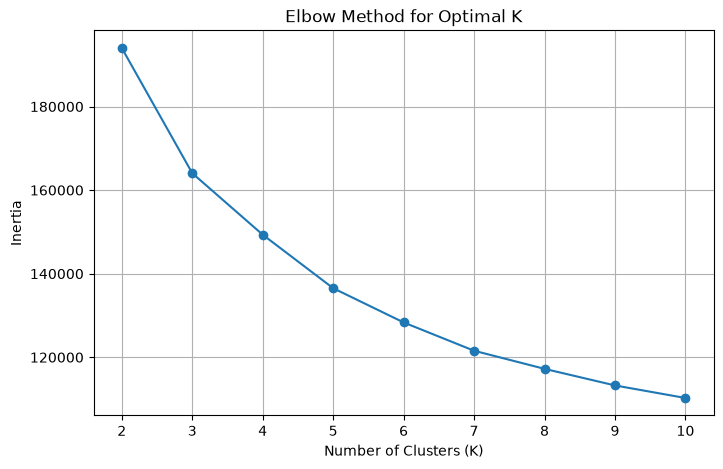

In [18]:
# Elbow Curve

plt.figure(figsize=(8, 5))

plt.plot(k_values, inertia, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')

plt.xticks(k_values)
plt.grid(True)

plt.show()

In [19]:
# Step 13: Silhouette Score for Cluster Evaluation

from sklearn.metrics import silhouette_score

silhouette_scores = []

k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    cluster_labels = kmeans.fit_predict(X_scaled)
    
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

# Display silhouette scores
print("K  |  Silhouette Score")
print("-" * 30)

for k, score in zip(k_values, silhouette_scores):
    print(f"{k}  |  {score:.4f}")

K  |  Silhouette Score
------------------------------
2  |  0.3624
3  |  0.2450
4  |  0.2406
5  |  0.1974
6  |  0.1765
7  |  0.1670
8  |  0.1654
9  |  0.1658
10  |  0.1659


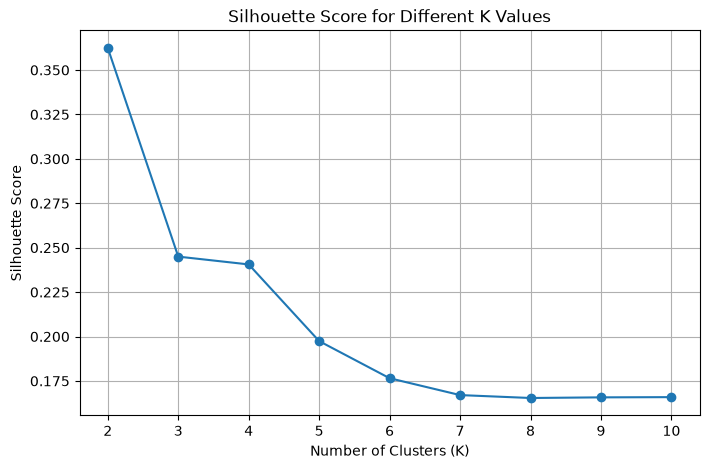

In [20]:
# Silhouette Score Plot

plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score for Different K Values')

plt.xticks(k_values)
plt.grid(True)

plt.show()

In [21]:
# Step 14: Compare Cluster Profiles for K = 2, 3 and 4

cluster_profiles = {}

for k in [2, 3, 4]:
    
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X_scaled)
    
    profile = df[clustering_features].copy()
    profile['Cluster'] = labels
    
    cluster_profiles[k] = profile.groupby('Cluster').mean().round(2)

for k, profile in cluster_profiles.items():
    print("\n" + "=" * 70)
    print(f"Cluster Profile for K = {k}")
    print("=" * 70)
    print(profile)


Cluster Profile for K = 2
         price_usd  rating  battery_life_rating  camera_rating  \
Cluster                                                          
0           690.21    2.08                 1.75           1.76   
1           689.20    4.11                 3.65           3.65   

         performance_rating  design_rating  display_rating  
Cluster                                                     
0                      1.76           1.76            1.76  
1                      3.65           3.64            3.66  

Cluster Profile for K = 3
         price_usd  rating  battery_life_rating  camera_rating  \
Cluster                                                          
0           688.98    3.21                 2.67           2.67   
1           690.07    4.40                 3.99           3.99   
2           690.07    1.65                 1.43           1.44   

         performance_rating  design_rating  display_rating  
Cluster                                      

In [22]:
# Step 15: Final K-Means Model with 4 Clusters

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans_final.fit_predict(X_scaled)

print("K-Means clustering completed successfully!")
print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())

K-Means clustering completed successfully!

Cluster Distribution:
Cluster
0    14177
1    16055
2     7548
3    12220
Name: count, dtype: int64


In [23]:
# Final Cluster Profiles

final_cluster_profile = (
    df.groupby('Cluster')[clustering_features]
      .mean()
      .round(2)
)

final_cluster_profile

,price_usd,rating,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating
Cluster,,,,,,,
0,653.09,4.48,4.08,4.07,4.07,4.06,4.07
1,685.74,1.65,1.44,1.45,1.45,1.45,1.45
2,1090.42,3.40,2.88,2.87,2.89,2.87,2.91
3,489.84,3.26,2.71,2.71,2.72,2.72,2.71


In [24]:
# Step 16: Brand Distribution Across Clusters

brand_cluster = pd.crosstab(
    df['Cluster'],
    df['brand']
)

print("Number of Products/Reviews by Brand within Each Cluster:")
print(brand_cluster)

Number of Products/Reviews by Brand within Each Cluster:
brand    Apple  Google  Motorola  OnePlus  Realme  Samsung  Xiaomi
Cluster                                                           
0         1617    2133      2153     2144    2160     1776    2194
1         2187    2424      2346     2338    2199     2256    2305
2         3070    1492        54      872       0     2060       0
3          270    1185      2508     1782    2773      960    2742


In [25]:
# Percentage Distribution of Brands Within Each Cluster

brand_cluster_percentage = pd.crosstab(
    df['Cluster'],
    df['brand'],
    normalize='index'
).mul(100).round(2)

print("Brand Percentage Distribution Within Each Cluster:")
print(brand_cluster_percentage)

Brand Percentage Distribution Within Each Cluster:
brand    Apple  Google  Motorola  OnePlus  Realme  Samsung  Xiaomi
Cluster                                                           
0        11.41   15.05     15.19    15.12   15.24    12.53   15.48
1        13.62   15.10     14.61    14.56   13.70    14.05   14.36
2        40.67   19.77      0.72    11.55    0.00    27.29    0.00
3         2.21    9.70     20.52    14.58   22.69     7.86   22.44


In [26]:
# Step 17A: Average Price by Cluster

cluster_price = (
    df.groupby('Cluster')['price_usd']
      .mean()
      .round(2)
)

fig = px.bar(
    x=cluster_price.index.astype(str),
    y=cluster_price.values,
    labels={
        'x': 'Cluster',
        'y': 'Average Price (USD)'
    },
    title='Average Price by Product Cluster',
    text=cluster_price.values.round(2)
)

fig.update_traces(textposition='outside')

fig.update_layout(
    xaxis_title='Product Cluster',
    yaxis_title='Average Price (USD)'
)

fig.show()

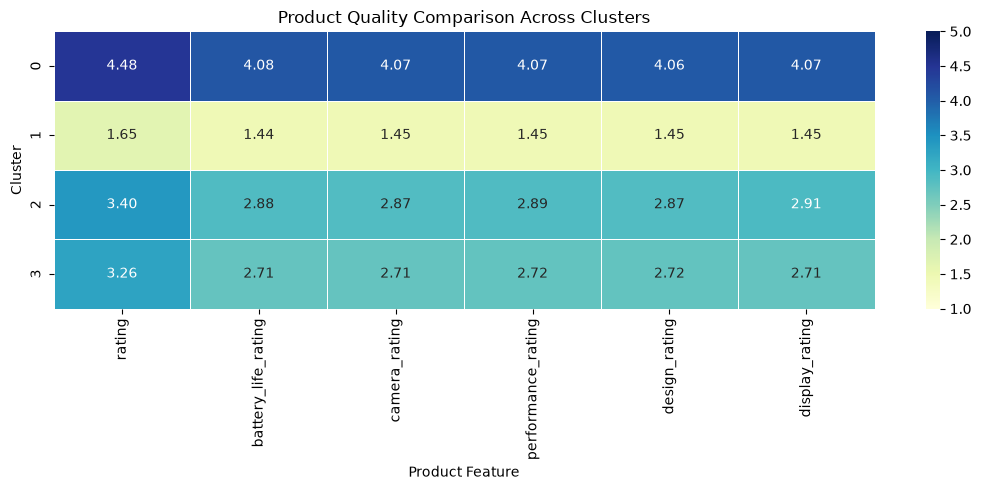

In [28]:
# Step 17B: Cluster Quality Comparison - Heatmap

quality_features = [
    'rating',
    'battery_life_rating',
    'camera_rating',
    'performance_rating',
    'design_rating',
    'display_rating'
]

cluster_quality = (
    df.groupby('Cluster')[quality_features]
      .mean()
      .round(2)
)

plt.figure(figsize=(11, 5))

sns.heatmap(
    cluster_quality,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=1,
    vmax=5,
    linewidths=0.5
)

plt.title('Product Quality Comparison Across Clusters')
plt.xlabel('Product Feature')
plt.ylabel('Cluster')

plt.tight_layout()
plt.show()

In [30]:
# Step 17C: Average Price vs Average Rating by Cluster

cluster_summary = (
    df.groupby('Cluster')[['price_usd', 'rating']]
      .mean()
      .reset_index()
      .round(2)
)

fig = px.scatter(
    cluster_summary,
    x='price_usd',
    y='rating',
    text='Cluster',
    size='rating',
    title='Average Price vs Average Rating by Cluster',
    labels={
        'price_usd': 'Average Price (USD)',
        'rating': 'Average Rating'
    }
)

fig.update_traces(
    textposition='top center'
)

fig.update_layout(
    xaxis_title='Average Price (USD)',
    yaxis_title='Average Rating (1–5)',
    yaxis=dict(range=[0, 5])
)

fig.show()

In [31]:
# Step 18: Prepare Recommendation Features

from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# Numerical features used for recommendation
recommendation_numeric_features = [
    'price_usd',
    'rating',
    'battery_life_rating',
    'camera_rating',
    'performance_rating',
    'design_rating',
    'display_rating'
]

# Scale numerical features
recommendation_scaler = StandardScaler()

numeric_scaled = recommendation_scaler.fit_transform(
    df[recommendation_numeric_features]
)

numeric_scaled_df = pd.DataFrame(
    numeric_scaled,
    columns=recommendation_numeric_features,
    index=df.index
)

# One-hot encode Brand
brand_encoded = pd.get_dummies(
    df['brand'],
    prefix='brand',
    dtype=int
)

# Combine numerical + brand features
recommendation_features = pd.concat(
    [numeric_scaled_df, brand_encoded],
    axis=1
)

print("Recommendation feature matrix created successfully!")

print("\nRecommendation Features:")
print(recommendation_features.columns.tolist())

print("\nRecommendation Matrix Shape:")
print(recommendation_features.shape)

recommendation_features.head()

Recommendation feature matrix created successfully!

Recommendation Features:
['price_usd', 'rating', 'battery_life_rating', 'camera_rating', 'performance_rating', 'design_rating', 'display_rating', 'brand_Apple', 'brand_Google', 'brand_Motorola', 'brand_OnePlus', 'brand_Realme', 'brand_Samsung', 'brand_Xiaomi']

Recommendation Matrix Shape:
(50000, 14)


,price_usd,rating,battery_life_rating,camera_rating,performance_rating,design_rating,display_rating,brand_Apple,brand_Google,brand_Motorola,brand_OnePlus,brand_Realme,brand_Samsung,brand_Xiaomi
0,-1.136372,-0.887951,-1.274238,-1.277067,0.207813,-0.531484,-1.273035,0,0,0,0,1,0,0
1,-1.231600,0.710838,0.209159,-0.533566,0.948996,0.212933,-0.533449,0,0,0,0,1,0,0
2,0.563817,0.710838,0.209159,1.696937,0.207813,-0.531484,0.945723,0,1,0,0,0,0,0
3,-0.092724,-0.088557,-1.274238,0.209935,-0.533370,-1.275902,-0.533449,0,0,0,0,0,0,1
4,0.330340,-0.088557,0.209159,0.209935,-0.533370,-0.531484,-1.273035,0,0,1,0,0,0,0


In [33]:
# Step 19: Cosine Similarity - Memory Efficient Approach

# Example: select one product using its dataframe index
selected_index = 0

# Get the selected product's feature vector
selected_product = recommendation_features.loc[[selected_index]]

# Calculate similarity against ALL products
similarity_scores = cosine_similarity(
    selected_product,
    recommendation_features
)[0]

print("Cosine similarity calculated successfully!")

print("Number of similarity scores:", len(similarity_scores))
print("Similarity scores shape:", similarity_scores.shape)

print("\nFirst 10 similarity scores:")
print(similarity_scores[:10])

Cosine similarity calculated successfully!
Number of similarity scores: 50000
Similarity scores shape: (50000,)

First 10 similarity scores:
[ 1.          0.47838123 -0.65212347  0.43820869  0.18129447 -0.67968648
  0.30712803  0.1273147  -0.01300534  0.60833196]


In [45]:
# Step 20: Define Recommendation Parameters and Weights

recommendation_features = [
    'price_usd',
    'rating',
    'performance_rating',
    'camera_rating',
    'battery_life_rating',
    'display_rating',
    'design_rating'
]

recommendation_weights = {
    'price_usd': 0.25,
    'rating': 0.15,
    'performance_rating': 0.15,
    'camera_rating': 0.10,
    'battery_life_rating': 0.10,
    'display_rating': 0.10,
    'design_rating': 0.05
}

brand_weight = 0.10

print("Recommendation parameters defined:\n")

for feature, weight in recommendation_weights.items():
    print(f"{feature}: {weight * 100:.0f}%")

print(f"Brand preference: {brand_weight * 100:.0f}%")

print(
    "\nTotal weight:",
    f"{(sum(recommendation_weights.values()) + brand_weight) * 100:.0f}%"
)

Recommendation parameters defined:

price_usd: 25%
rating: 15%
performance_rating: 15%
camera_rating: 10%
battery_life_rating: 10%
display_rating: 10%
design_rating: 5%
Brand preference: 10%

Total weight: 100%


In [46]:
# Step 21: Create Product-Level Dataset

product_features = [
    'price_usd',
    'rating',
    'performance_rating',
    'camera_rating',
    'battery_life_rating',
    'display_rating',
    'design_rating'
]

product_df = (
    df.groupby(['brand', 'model'])[product_features]
      .mean()
      .reset_index()
)

print("Product-level dataset created!")
print("Unique products:", len(product_df))
print("Columns:", list(product_df.columns))

product_df.head()

Product-level dataset created!
Unique products: 22
Columns: ['brand', 'model', 'price_usd', 'rating', 'performance_rating', 'camera_rating', 'battery_life_rating', 'display_rating', 'design_rating']


,brand,model,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating
0,Apple,iPhone 13,1108.262713,3.144312,2.765139,2.754952,2.754952,2.710243,2.765139
1,Apple,iPhone 14,1099.211140,3.158277,2.723714,2.781879,2.738255,2.758949,2.773490
2,Apple,iPhone 15 Pro,1103.403376,3.078639,2.661461,2.707195,2.677635,2.691021,2.675404
3,Apple,iPhone SE,1103.378773,3.095768,2.732183,2.703786,2.727728,2.735523,2.690980
4,Google,Pixel 6,807.920273,3.105507,2.689786,2.709962,2.712064,2.715427,2.706179


In [47]:
# Step 22: Scale Product Features for Cosine Similarity

from sklearn.preprocessing import StandardScaler

similarity_scaler = StandardScaler()

product_scaled = similarity_scaler.fit_transform(
    product_df[product_features]
)

product_scaled_df = pd.DataFrame(
    product_scaled,
    columns=product_features,
    index=product_df.index
)

print("Product similarity features scaled successfully!")
print("Shape:", product_scaled_df.shape)

product_scaled_df.head()

Product similarity features scaled successfully!
Shape: (22, 7)


,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating
0,1.541696,1.414402,1.391390,1.441951,1.844734,-0.347803,1.753676
1,1.504631,1.987521,0.179942,2.483244,1.019224,1.547464,2.037855
2,1.521798,-1.280805,-1.640591,-0.404846,-1.977878,-1.095817,-1.299817
3,1.521697,-0.577828,0.427612,-0.536653,0.498771,0.635920,-0.769807
4,0.311847,-0.178178,-0.812262,-0.297824,-0.275692,-0.146105,-0.252610


In [48]:
# Step 23: Define User Preferences

user_preferences = {
    'brand': 'Apple',
    'price_usd': 1000,
    'rating': 4,
    'performance_rating': 4,
    'camera_rating': 4,
    'battery_life_rating': 4,
    'display_rating': 4,
    'design_rating': 4
}

print("User preferences:")
for feature, value in user_preferences.items():
    print(f"{feature}: {value}")

User preferences:
brand: Apple
price_usd: 1000
rating: 4
performance_rating: 4
camera_rating: 4
battery_life_rating: 4
display_rating: 4
design_rating: 4


In [50]:
# Step 24: Normalize User Preferences Using Meaningful Feature Ranges

# Price range from the cleaned dataset
price_min = df['price_usd'].min()
price_max = df['price_usd'].max()

# Normalize user price
user_price_normalized = (
    (user_preferences['price_usd'] - price_min)
    / (price_max - price_min)
)

# Normalize 1-5 rating/specification values
user_rating_normalized = {}

rating_features = [
    'rating',
    'performance_rating',
    'camera_rating',
    'battery_life_rating',
    'display_rating',
    'design_rating'
]

for feature in rating_features:
    user_rating_normalized[feature] = (
        user_preferences[feature] - 1
    ) / (5 - 1)

# Create normalized user vector
user_normalized = pd.DataFrame([{
    'price_usd': user_price_normalized,
    'rating': user_rating_normalized['rating'],
    'performance_rating': user_rating_normalized['performance_rating'],
    'camera_rating': user_rating_normalized['camera_rating'],
    'battery_life_rating': user_rating_normalized['battery_life_rating'],
    'display_rating': user_rating_normalized['display_rating'],
    'design_rating': user_rating_normalized['design_rating']
}])

print("User preferences normalized successfully!")
print("\nPrice range in dataset:")
print(f"Minimum price: ${price_min:.2f}")
print(f"Maximum price: ${price_max:.2f}")

print("\nNormalized user vector:")
user_normalized

User preferences normalized successfully!

Price range in dataset:
Minimum price: $180.02
Maximum price: $1499.89

Normalized user vector:


,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating
0,0.621258,0.75,0.75,0.75,0.75,0.75,0.75


In [51]:
# Step 25: Normalize Product Features

product_normalized = product_df.copy()

# Normalize price using the actual dataset price range
product_normalized['price_usd'] = (
    (product_normalized['price_usd'] - price_min)
    / (price_max - price_min)
)

# Normalize all 1-5 rating/specification features
for feature in rating_features:
    product_normalized[feature] = (
        (product_normalized[feature] - 1) / (5 - 1)
    )

# Keep only recommendation features
product_normalized_features = product_normalized[
    product_features
].copy()

print("Product features normalized successfully!")
print("Shape:", product_normalized_features.shape)

product_normalized_features.head()

Product features normalized successfully!
Shape: (22, 7)


,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating
0,0.703283,0.536078,0.441285,0.438738,0.438738,0.427561,0.441285
1,0.696426,0.539569,0.430928,0.445470,0.434564,0.439737,0.443372
2,0.699602,0.519660,0.415365,0.426799,0.419409,0.422755,0.418851
3,0.699583,0.523942,0.433046,0.425947,0.431932,0.433881,0.422745
4,0.475729,0.526377,0.422446,0.427491,0.428016,0.428857,0.426545


In [52]:
# Step 26: Calculate Feature-Level Similarity

feature_similarity = pd.DataFrame(index=product_df.index)

for feature in product_features:
    feature_similarity[feature] = (
        1 - abs(
            product_normalized_features[feature]
            - user_normalized.iloc[0][feature]
        )
    )

print("Feature-level similarity calculated!")
print("Shape:", feature_similarity.shape)

feature_similarity.head()

Feature-level similarity calculated!
Shape: (22, 7)


,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating
0,0.917975,0.786078,0.691285,0.688738,0.688738,0.677561,0.691285
1,0.924833,0.789569,0.680928,0.695470,0.684564,0.689737,0.693372
2,0.921656,0.769660,0.665365,0.676799,0.669409,0.672755,0.668851
3,0.921675,0.773942,0.683046,0.675947,0.681932,0.683881,0.672745
4,0.854471,0.776377,0.672446,0.677491,0.678016,0.678857,0.676545


In [53]:
# Step 27: Calculate Cosine Similarity

user_product_vector = user_normalized[product_features]

cosine_scores = cosine_similarity(
    user_product_vector,
    product_normalized_features
)[0]

cosine_similarity_df = pd.DataFrame({
    'index': product_df.index,
    'cosine_similarity': cosine_scores
})

print("Cosine Similarity calculated!")
print("Number of products compared:", len(cosine_scores))

cosine_similarity_df.head()

Cosine Similarity calculated!
Number of products compared: 22


,index,cosine_similarity
0,0,0.969542
1,1,0.970842
2,2,0.965825
3,3,0.968153
4,4,0.993300


In [54]:
# Step 28: Calculate Brand-Profile Similarity

brand_profiles = (
    product_normalized
    .groupby('brand')[product_features]
    .mean()
)

selected_brand = user_preferences['brand']

selected_brand_profile = brand_profiles.loc[selected_brand].values.reshape(1, -1)

brand_cosine_scores = cosine_similarity(
    selected_brand_profile,
    brand_profiles
)[0]

brand_similarity_df = pd.DataFrame({
    'brand': brand_profiles.index,
    'brand_similarity': brand_cosine_scores
})

print("Brand-profile similarity calculated!")
print("\nSelected brand:", selected_brand)

brand_similarity_df.sort_values(
    'brand_similarity',
    ascending=False
)

Brand-profile similarity calculated!

Selected brand: Apple


,brand,brand_similarity
0,Apple,1.000000
5,Samsung,0.994827
1,Google,0.987415
3,OnePlus,0.971719
2,Motorola,0.941745
6,Xiaomi,0.928216
4,Realme,0.912600


In [55]:
# Step 29: Calculate Final Recommendation Score

final_scores = feature_similarity.copy()

# Add brand information to each product
final_scores['brand'] = product_df['brand'].values
final_scores['model'] = product_df['model'].values

# Add brand-profile similarity
brand_similarity_map = dict(
    zip(
        brand_similarity_df['brand'],
        brand_similarity_df['brand_similarity']
    )
)

final_scores['brand_similarity'] = (
    final_scores['brand'].map(brand_similarity_map)
)

# Calculate weighted feature score
final_scores['feature_score'] = (
    final_scores['price_usd'] * 0.25 +
    final_scores['rating'] * 0.15 +
    final_scores['performance_rating'] * 0.15 +
    final_scores['camera_rating'] * 0.10 +
    final_scores['battery_life_rating'] * 0.10 +
    final_scores['display_rating'] * 0.10 +
    final_scores['design_rating'] * 0.05
)

# Add brand preference contribution
final_scores['final_score'] = (
    final_scores['feature_score'] * 0.90 +
    final_scores['brand_similarity'] * 0.10
)

print("Final recommendation scores calculated!")

final_scores[
    [
        'brand',
        'model',
        'feature_score',
        'brand_similarity',
        'final_score'
    ]
].head()

Final recommendation scores calculated!


,brand,model,feature_score,brand_similarity,final_score
0,Apple,iPhone 13,0.691166,1.000000,0.722049
1,Apple,iPhone 14,0.693429,1.000000,0.724086
2,Apple,iPhone 15 Pro,0.681007,1.000000,0.712906
3,Apple,iPhone SE,0.686780,1.000000,0.718102
4,Google,Pixel 6,0.668205,0.987415,0.700126


In [56]:
# Step 30: Calculate Final Recommendation Score with Cosine Similarity

final_scores['cosine_similarity'] = cosine_scores

final_scores['final_score'] = (
    final_scores['price_usd'] * 0.20 +
    final_scores['rating'] * 0.12 +
    final_scores['performance_rating'] * 0.12 +
    final_scores['camera_rating'] * 0.08 +
    final_scores['battery_life_rating'] * 0.08 +
    final_scores['display_rating'] * 0.08 +
    final_scores['design_rating'] * 0.04 +
    final_scores['cosine_similarity'] * 0.18 +
    final_scores['brand_similarity'] * 0.10
)

print("Final recommendation score updated successfully!")

print("\nWeight total:",
      (0.20 + 0.12 + 0.12 + 0.08 + 0.08 +
       0.08 + 0.04 + 0.18 + 0.10) * 100,
      "%")

final_scores[
    [
        'brand',
        'model',
        'feature_score',
        'cosine_similarity',
        'brand_similarity',
        'final_score'
    ]
].head()

Final recommendation score updated successfully!

Weight total: 99.99999999999999 %


,brand,model,feature_score,cosine_similarity,brand_similarity,final_score
0,Apple,iPhone 13,0.691166,0.969542,1.000000,0.827450
1,Apple,iPhone 14,0.693429,0.970842,1.000000,0.829494
2,Apple,iPhone 15 Pro,0.681007,0.965825,1.000000,0.818654
3,Apple,iPhone SE,0.686780,0.968153,1.000000,0.823692
4,Google,Pixel 6,0.668205,0.993300,0.987415,0.812099


In [57]:
# Step 31: Rank All Products by Final Recommendation Score

recommendations = final_scores.sort_values(
    'final_score',
    ascending=False
).reset_index(drop=True)

print("Recommendations ranked successfully!")
print("Total products considered:", len(recommendations))

recommendations[
    [
        'brand',
        'model',
        'final_score',
        'cosine_similarity',
        'brand_similarity'
    ]
].head(10)

Recommendations ranked successfully!
Total products considered: 22


,brand,model,final_score,cosine_similarity,brand_similarity
0,Samsung,Galaxy Note 20,0.830555,0.988597,0.994827
1,Apple,iPhone 14,0.829494,0.970842,1.000000
2,Samsung,Galaxy Z Flip,0.829396,0.988353,0.994827
3,Apple,iPhone 13,0.827450,0.969542,1.000000
4,Apple,iPhone SE,0.823692,0.968153,1.000000
5,Samsung,Galaxy A55,0.822534,0.986238,0.994827
6,Samsung,Galaxy S24,0.819313,0.986679,0.994827
7,Apple,iPhone 15 Pro,0.818654,0.965825,1.000000
8,Google,Pixel 7a,0.814760,0.993919,0.987415
9,Google,Pixel 8,0.812306,0.994207,0.987415


In [58]:
# Step 32: Prepare Top 10 Recommendations

top_10_recommendations = recommendations[
    [
        'brand',
        'model',
        'final_score',
        'cosine_similarity',
        'brand_similarity'
    ]
].head(10).copy()

top_10_recommendations

,brand,model,final_score,cosine_similarity,brand_similarity
0,Samsung,Galaxy Note 20,0.830555,0.988597,0.994827
1,Apple,iPhone 14,0.829494,0.970842,1.000000
2,Samsung,Galaxy Z Flip,0.829396,0.988353,0.994827
3,Apple,iPhone 13,0.827450,0.969542,1.000000
4,Apple,iPhone SE,0.823692,0.968153,1.000000
5,Samsung,Galaxy A55,0.822534,0.986238,0.994827
6,Samsung,Galaxy S24,0.819313,0.986679,0.994827
7,Apple,iPhone 15 Pro,0.818654,0.965825,1.000000
8,Google,Pixel 7a,0.814760,0.993919,0.987415
9,Google,Pixel 8,0.812306,0.994207,0.987415


In [59]:
# Step 33: Add Product Details to Recommendations

recommendation_details = recommendations[
    [
        'brand',
        'model',
        'final_score',
        'cosine_similarity',
        'brand_similarity'
    ]
].head(10).copy()

recommendation_details = recommendation_details.merge(
    product_df,
    on=['brand', 'model'],
    how='left'
)

recommendation_details = recommendation_details[
    [
        'brand',
        'model',
        'price_usd',
        'rating',
        'performance_rating',
        'camera_rating',
        'battery_life_rating',
        'display_rating',
        'design_rating',
        'final_score'
    ]
]

recommendation_details

,brand,model,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating,final_score
0,Samsung,Galaxy Note 20,899.738559,3.140861,2.756847,2.729458,2.740637,2.725545,2.747345,0.830555
1,Apple,iPhone 14,1099.211140,3.158277,2.723714,2.781879,2.738255,2.758949,2.773490,0.829494
2,Samsung,Galaxy Z Flip,899.372942,3.122520,2.750292,2.739207,2.725788,2.742124,2.693116,0.829396
3,Apple,iPhone 13,1108.262713,3.144312,2.765139,2.754952,2.754952,2.710243,2.765139,0.827450
4,Apple,iPhone SE,1103.378773,3.095768,2.732183,2.703786,2.727728,2.735523,2.690980,0.823692
5,Samsung,Galaxy A55,904.532405,3.074385,2.661633,2.676174,2.721477,2.651007,2.694072,0.822534
6,Samsung,Galaxy S24,894.110220,3.058489,2.650199,2.663827,2.678024,2.670642,2.676320,0.819313
7,Apple,iPhone 15 Pro,1103.403376,3.078639,2.661461,2.707195,2.677635,2.691021,2.675404,0.818654
8,Google,Pixel 7a,806.820553,3.115478,2.725689,2.732172,2.715964,2.748784,2.721232,0.814760
9,Google,Pixel 8,798.969665,3.106410,2.691244,2.715543,2.731881,2.737746,2.743611,0.812306


In [60]:
# Step 34A: Create Recommendation Function

def get_recommendations(
    brand,
    price_usd,
    rating,
    performance_rating,
    camera_rating,
    battery_life_rating,
    display_rating,
    design_rating,
    top_n=10
):
    
    # Create user preference dictionary
    user_preferences_test = {
        'brand': brand,
        'price_usd': price_usd,
        'rating': rating,
        'performance_rating': performance_rating,
        'camera_rating': camera_rating,
        'battery_life_rating': battery_life_rating,
        'display_rating': display_rating,
        'design_rating': design_rating
    }

    # Normalize price
    user_price_normalized = (
        (price_usd - price_min)
        / (price_max - price_min)
    )

    # Normalize rating/specification inputs
    user_rating_normalized = {}

    for feature in rating_features:
        user_rating_normalized[feature] = (
            user_preferences_test[feature] - 1
        ) / 4

    user_normalized_test = pd.DataFrame([{
        'price_usd': user_price_normalized,
        'rating': user_rating_normalized['rating'],
        'performance_rating': user_rating_normalized['performance_rating'],
        'camera_rating': user_rating_normalized['camera_rating'],
        'battery_life_rating': user_rating_normalized['battery_life_rating'],
        'display_rating': user_rating_normalized['display_rating'],
        'design_rating': user_rating_normalized['design_rating']
    }])

    # Feature-level similarity
    feature_similarity_test = pd.DataFrame(
        index=product_df.index
    )

    for feature in product_features:
        feature_similarity_test[feature] = (
            1 - abs(
                product_normalized_features[feature]
                - user_normalized_test.iloc[0][feature]
            )
        )

    # Cosine similarity
    cosine_scores_test = cosine_similarity(
        user_normalized_test[product_features],
        product_normalized_features
    )[0]

    # Brand-profile similarity
    selected_brand_profile_test = (
        brand_profiles.loc[brand].values.reshape(1, -1)
    )

    brand_cosine_scores_test = cosine_similarity(
        selected_brand_profile_test,
        brand_profiles
    )[0]

    brand_similarity_map_test = dict(
        zip(
            brand_profiles.index,
            brand_cosine_scores_test
        )
    )

    # Build result
    result = feature_similarity_test.copy()

    result['brand'] = product_df['brand'].values
    result['model'] = product_df['model'].values

    result['brand_similarity'] = (
        result['brand'].map(brand_similarity_map_test)
    )

    result['cosine_similarity'] = cosine_scores_test

    # Final weighted score
    result['final_score'] = (
        result['price_usd'] * 0.20 +
        result['rating'] * 0.12 +
        result['performance_rating'] * 0.12 +
        result['camera_rating'] * 0.08 +
        result['battery_life_rating'] * 0.08 +
        result['display_rating'] * 0.08 +
        result['design_rating'] * 0.04 +
        result['cosine_similarity'] * 0.18 +
        result['brand_similarity'] * 0.10
    )

    # Rank recommendations
    result = result.sort_values(
        'final_score',
        ascending=False
    )

    # Add product details
    result = result[
        ['brand', 'model', 'final_score']
    ].head(top_n)

    result = result.merge(
        product_df,
        on=['brand', 'model'],
        how='left'
    )

    return result[
        [
            'brand',
            'model',
            'price_usd',
            'rating',
            'performance_rating',
            'camera_rating',
            'battery_life_rating',
            'display_rating',
            'design_rating',
            'final_score'
        ]
    ].reset_index(drop=True)


print("Recommendation function created successfully!")

Recommendation function created successfully!


In [61]:
# Step 34B: Test Recommendation Function

test_recommendations = get_recommendations(
    brand='Apple',
    price_usd=1000,
    rating=4,
    performance_rating=4,
    camera_rating=4,
    battery_life_rating=4,
    display_rating=4,
    design_rating=4,
    top_n=10
)

test_recommendations

,brand,model,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating,final_score
0,Samsung,Galaxy Note 20,899.738559,3.140861,2.756847,2.729458,2.740637,2.725545,2.747345,0.830555
1,Apple,iPhone 14,1099.211140,3.158277,2.723714,2.781879,2.738255,2.758949,2.773490,0.829494
2,Samsung,Galaxy Z Flip,899.372942,3.122520,2.750292,2.739207,2.725788,2.742124,2.693116,0.829396
3,Apple,iPhone 13,1108.262713,3.144312,2.765139,2.754952,2.754952,2.710243,2.765139,0.827450
4,Apple,iPhone SE,1103.378773,3.095768,2.732183,2.703786,2.727728,2.735523,2.690980,0.823692
5,Samsung,Galaxy A55,904.532405,3.074385,2.661633,2.676174,2.721477,2.651007,2.694072,0.822534
6,Samsung,Galaxy S24,894.110220,3.058489,2.650199,2.663827,2.678024,2.670642,2.676320,0.819313
7,Apple,iPhone 15 Pro,1103.403376,3.078639,2.661461,2.707195,2.677635,2.691021,2.675404,0.818654
8,Google,Pixel 7a,806.820553,3.115478,2.725689,2.732172,2.715964,2.748784,2.721232,0.814760
9,Google,Pixel 8,798.969665,3.106410,2.691244,2.715543,2.731881,2.737746,2.743611,0.812306


In [62]:
# Step 34C: Test Different User Preferences

test_recommendations_2 = get_recommendations(
    brand='Samsung',
    price_usd=700,
    rating=3,
    performance_rating=3,
    camera_rating=3,
    battery_life_rating=3,
    display_rating=3,
    design_rating=3,
    top_n=10
)

test_recommendations_2

,brand,model,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating,final_score
0,OnePlus,OnePlus Nord 3,674.664430,3.124790,2.736134,2.734034,2.732773,2.740756,2.676891,0.963889
1,OnePlus,OnePlus 12,670.612542,3.120103,2.721050,2.746449,2.727508,2.709427,2.718898,0.962929
2,OnePlus,OnePlus 11R,672.786580,3.115906,2.713522,2.707768,2.704480,2.716811,2.703247,0.961867
3,Google,Pixel 8,798.969665,3.106410,2.691244,2.715543,2.731881,2.737746,2.743611,0.952250
4,Google,Pixel 7a,806.820553,3.115478,2.725689,2.732172,2.715964,2.748784,2.721232,0.951772
5,Google,Pixel 6,807.920273,3.105507,2.689786,2.709962,2.712064,2.715427,2.706179,0.949364
6,Samsung,Galaxy Z Flip,899.372942,3.122520,2.750292,2.739207,2.725788,2.742124,2.693116,0.937222
7,Samsung,Galaxy Note 20,899.738559,3.140861,2.756847,2.729458,2.740637,2.725545,2.747345,0.937176
8,Motorola,Razr 40,506.152931,3.101044,2.730271,2.683925,2.713152,2.724008,2.724843,0.935014
9,Motorola,Edge 50,508.697626,3.074730,2.704536,2.701512,2.674730,2.707559,2.688553,0.934383


In [63]:
# Step 34D: Test Premium User Preferences

test_recommendations_3 = get_recommendations(
    brand='Google',
    price_usd=1200,
    rating=5,
    performance_rating=5,
    camera_rating=5,
    battery_life_rating=5,
    display_rating=5,
    design_rating=5,
    top_n=10
)

test_recommendations_3

,brand,model,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating,final_score
0,Apple,iPhone 13,1108.262713,3.144312,2.765139,2.754952,2.754952,2.710243,2.765139,0.697792
1,Apple,iPhone 14,1099.211140,3.158277,2.723714,2.781879,2.738255,2.758949,2.773490,0.697115
2,Apple,iPhone SE,1103.378773,3.095768,2.732183,2.703786,2.727728,2.735523,2.690980,0.692531
3,Apple,iPhone 15 Pro,1103.403376,3.078639,2.661461,2.707195,2.677635,2.691021,2.675404,0.687471
4,Samsung,Galaxy Note 20,899.738559,3.140861,2.756847,2.729458,2.740637,2.725545,2.747345,0.670081
5,Samsung,Galaxy Z Flip,899.372942,3.122520,2.750292,2.739207,2.725788,2.742124,2.693116,0.668913
6,Samsung,Galaxy A55,904.532405,3.074385,2.661633,2.676174,2.721477,2.651007,2.694072,0.662000
7,Samsung,Galaxy S24,894.110220,3.058489,2.650199,2.663827,2.678024,2.670642,2.676320,0.658789
8,Google,Pixel 7a,806.820553,3.115478,2.725689,2.732172,2.715964,2.748784,2.721232,0.655374
9,Google,Pixel 8,798.969665,3.106410,2.691244,2.715543,2.731881,2.737746,2.743611,0.652932


In [64]:
# Step 34E: Test Low-Budget Realme Preferences

test_recommendations_4 = get_recommendations(
    brand='Realme',
    price_usd=500,
    rating=3,
    performance_rating=3,
    camera_rating=3,
    battery_life_rating=3,
    display_rating=3,
    design_rating=3,
    top_n=10
)

test_recommendations_4

,brand,model,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating,final_score
0,Motorola,Razr 40,506.152931,3.101044,2.730271,2.683925,2.713152,2.724008,2.724843,0.966678
1,Motorola,Moto G Power,504.606086,3.124202,2.716291,2.706083,2.715015,2.719268,2.716291,0.966043
2,Motorola,Edge 50,508.697626,3.074730,2.704536,2.701512,2.674730,2.707559,2.688553,0.965188
3,Xiaomi,Poco X6,450.266597,3.102752,2.763972,2.728719,2.711522,2.716251,2.756234,0.962386
4,Xiaomi,Redmi Note 13,449.782007,3.108907,2.717004,2.723887,2.721053,2.697976,2.709312,0.959900
5,Xiaomi,Mi 13 Pro,448.914093,3.087117,2.667076,2.698569,2.702249,2.710838,2.669530,0.957876
6,Realme,Realme 12 Pro,393.897752,3.136917,2.763225,2.714286,2.724470,2.758416,2.734088,0.953173
7,Realme,Realme Narzo 70,392.706779,3.119544,2.745065,2.729219,2.736725,2.733667,2.714484,0.952851
8,OnePlus,OnePlus 12,670.612542,3.120103,2.721050,2.746449,2.727508,2.709427,2.718898,0.939269
9,OnePlus,OnePlus Nord 3,674.664430,3.124790,2.736134,2.734034,2.732773,2.740756,2.676891,0.938951


In [65]:
# Step 35: Prepare Final Recommendation Dataset

recommendation_dataset = product_df[
    [
        'brand',
        'model',
        'price_usd',
        'rating',
        'performance_rating',
        'camera_rating',
        'battery_life_rating',
        'display_rating',
        'design_rating'
    ]
].copy()

print("Final recommendation dataset prepared!")
print("Shape:", recommendation_dataset.shape)

recommendation_dataset.head(10)

Final recommendation dataset prepared!
Shape: (22, 9)


,brand,model,price_usd,rating,performance_rating,camera_rating,battery_life_rating,display_rating,design_rating
0,Apple,iPhone 13,1108.262713,3.144312,2.765139,2.754952,2.754952,2.710243,2.765139
1,Apple,iPhone 14,1099.211140,3.158277,2.723714,2.781879,2.738255,2.758949,2.773490
2,Apple,iPhone 15 Pro,1103.403376,3.078639,2.661461,2.707195,2.677635,2.691021,2.675404
3,Apple,iPhone SE,1103.378773,3.095768,2.732183,2.703786,2.727728,2.735523,2.690980
4,Google,Pixel 6,807.920273,3.105507,2.689786,2.709962,2.712064,2.715427,2.706179
5,Google,Pixel 7a,806.820553,3.115478,2.725689,2.732172,2.715964,2.748784,2.721232
6,Google,Pixel 8,798.969665,3.106410,2.691244,2.715543,2.731881,2.737746,2.743611
7,Motorola,Edge 50,508.697626,3.074730,2.704536,2.701512,2.674730,2.707559,2.688553
8,Motorola,Moto G Power,504.606086,3.124202,2.716291,2.706083,2.715015,2.719268,2.716291
9,Motorola,Razr 40,506.152931,3.101044,2.730271,2.683925,2.713152,2.724008,2.724843


In [66]:
# Step 36: Create Recommendation Model Package

import pickle

model_package = {
    'product_df': product_df,
    'product_normalized_features': product_normalized_features,
    'brand_profiles': brand_profiles,
    'price_min': price_min,
    'price_max': price_max,
    'product_features': product_features,
    'rating_features': rating_features,
    'recommendation_weights': {
        'price_usd': 0.20,
        'rating': 0.12,
        'performance_rating': 0.12,
        'camera_rating': 0.08,
        'battery_life_rating': 0.08,
        'display_rating': 0.08,
        'design_rating': 0.04,
        'cosine_similarity': 0.18,
        'brand_similarity': 0.10
    }
}

pkl_path = r"D:\Data Science\vscode\Mobile_Product_Segmentation\Output\mobile_recommendation_model.pkl"

with open(pkl_path, 'wb') as file:
    pickle.dump(model_package, file)

print("Recommendation model package saved successfully!")
print("File:", pkl_path)

Recommendation model package saved successfully!
File: D:\Data Science\vscode\Mobile_Product_Segmentation\Output\mobile_recommendation_model.pkl


In [67]:
# Step 37: Verify Saved Recommendation Model Package

import pickle

pkl_path = r"D:\Data Science\vscode\Mobile_Product_Segmentation\Output\mobile_recommendation_model.pkl"

with open(pkl_path, 'rb') as file:
    loaded_package = pickle.load(file)

print("PKL file loaded successfully!\n")

print("Objects stored in the package:")
for key in loaded_package.keys():
    print("-", key)

print("\nProduct dataset shape:",
      loaded_package['product_df'].shape)

print("Normalized features shape:",
      loaded_package['product_normalized_features'].shape)

print("Brand profiles shape:",
      loaded_package['brand_profiles'].shape)

print("\nPrice range:")
print(
    f"${loaded_package['price_min']:.2f} "
    f"to "
    f"${loaded_package['price_max']:.2f}"
)

print("\nRecommendation weights:")
print(loaded_package['recommendation_weights'])

PKL file loaded successfully!

Objects stored in the package:
- product_df
- product_normalized_features
- brand_profiles
- price_min
- price_max
- product_features
- rating_features
- recommendation_weights

Product dataset shape: (22, 9)
Normalized features shape: (22, 7)
Brand profiles shape: (7, 7)

Price range:
$180.02 to $1499.89

Recommendation weights:
{'price_usd': 0.2, 'rating': 0.12, 'performance_rating': 0.12, 'camera_rating': 0.08, 'battery_life_rating': 0.08, 'display_rating': 0.08, 'design_rating': 0.04, 'cosine_similarity': 0.18, 'brand_similarity': 0.1}
